# Lab01 - Sprint 1

In [4]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import scipy.stats as stats

sensors = pd.read_csv('ASE10.csv', sep = ';')

sensors.head(5)

,date,ASE_NO2,ASE_NO,ASE_CO,ASE_Ox,ASE_T,ASE_HR,ASE_PA,SUD3_NO2,SUD3_NO,QDP_NO,QDP_NO2,QDP_CO,Location
0,2021-10-20 14:00,29123.75000,43733.48438,40791.60938,29087.65625,23.253516,54.889016,1006.269444,11.2,3.5,15.6,22.7,0.139,SUD3
1,2021-10-20 15:00,29084.31434,42984.14706,40922.12408,29067.22335,22.838591,56.928588,1005.413194,17.8,6.2,20.7,27.1,0.148,SUD3
2,2021-10-20 16:00,29119.26563,42667.14063,40680.23438,29099.71875,22.751450,54.193586,1004.264236,13.3,2.1,23.9,30.2,0.178,SUD3
3,2021-10-20 17:00,29110.03125,42470.15625,40709.89063,29097.42188,22.614907,54.335088,1002.840972,13.4,1.1,12.6,28.7,0.129,SUD3
4,2021-10-20 18:00,29108.90165,42257.46048,40683.00092,29086.15717,21.929122,55.553496,1001.325000,11.8,0.9,8.3,32.6,0.122,SUD3


## Random Variable 01: Сигнал сенсора NO2


### Description
Случайная величина 1 - значение напряжения на электрохимическом сенсоре NO2, измеряемое на автомобильном перекрестке. Показание сенсора нельзя рассчитать по формуле, так как на концентрацию газа в воздухе влияет количество машин на светофоре и порывы ветра. Также присутствует погрешность самого сенсора и броуновское движение молекул газа.

### EDA & Distribution


Размер данных до очистки: 3739 наблюдений.
Размер данных после очистки: 3686 наблюдений.



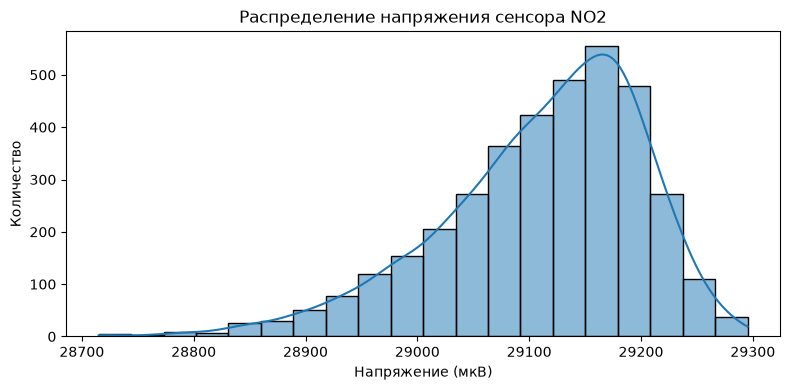

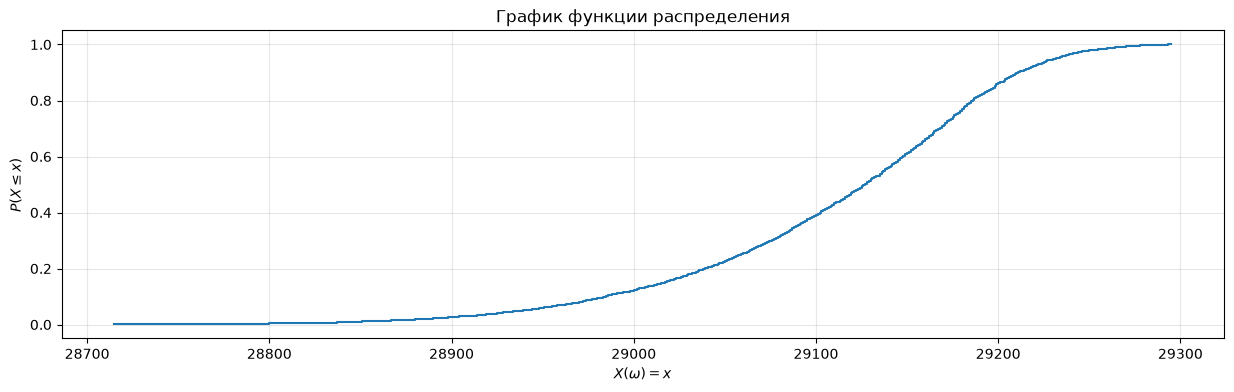


Сумма: 107306226.23449999
Среднее: 29111.835657759086
Медиана: 29128.038145
Минимум: 28715.0
Максимум: 29295.28125
Стандартное отклонение: 90.41962706444696
95-й перцентиль: 29233.165215
Дисперсия: 8175.708958473668
Мода: 29126.09375


In [39]:
no2_all = sensors['ASE_NO2']
no2 = sensors['ASE_NO2'].dropna()

print(f"\nРазмер данных до очистки: {no2_all.shape[0]} наблюдений.")
print(f"Размер данных после очистки: {no2.shape[0]} наблюдений.\n")

no2.head(5)

#распределения
fig, axes = plt.subplots(figsize=(8, 4))

sns.histplot(
    data=no2,
    kde=True,
    ax=axes,
    bins = 20
)
axes.set_title("Распределение напряжения сенсора NO2")
axes.set_xlabel("Напряжение (мкВ)")
axes.set_ylabel("Количество")

plt.tight_layout()
plt.show()


#график ф-ции распределения
no2_round = no2.apply(lambda x: int(round(x)))
voltage = no2_round.value_counts().reset_index()
voltage['p_i'] = voltage['count'].apply(lambda x: x/no2.shape[0])

p_accum = 0

def P_func(x):
    global p_accum
    p_accum += x
    return p_accum

voltage = voltage.sort_values(by='ASE_NO2')
voltage['P'] = voltage ['p_i'].apply(lambda x: P_func(x))

fig, ax = plt.subplots(figsize=(15, 4))
ax.step(voltage['ASE_NO2'],voltage['P'])
ax.set_title("График функции распределения")
ax.set_xlabel(r"$X(\omega) = x$")
ax.set_ylabel(r"$P(X \leq x)$")
ax.grid(True, alpha=0.3)

plt.show()

#остальные метрики
print(f"\nСумма:", no2.sum())
print("Среднее:", no2.mean())
print("Медиана:", no2.median())
print("Минимум:", no2.min())
print("Максимум:", no2.max())
print("Стандартное отклонение:", no2.std())
print("95-й перцентиль:", no2.quantile(0.95))
print("Дисперсия:", no2.var())
print("Мода:", no2.mode().iloc[0])


#### Математическая база распределения
Сенсор измеряет напряжение электрода, на что влияет множество мелких случайных факторов (ветер, машины, погрешность прибора). Если случайная величина формируется под воздействием множества независимых факторов, ее распределение стремится к нормальному.
Но физически - повышение концентрации NO2 понижает показатель датчика. Эти скачки концентрации (например, из-за частых автомобильных пробок в месте измерения) привело к ассиметрии графика распределения и образованию вытянутого левого хвоста.

Математически плотность вероятности ассиметричного нормального распределение задается:
$$f(x) = \frac{2}{\omega} \phi\left(\frac{x - \xi}{\omega}\right) \Phi\left(\alpha \left(\frac{x - \xi}{\omega}\right)\right)$$

Где:
* $\phi(t)$ — стандартная нормальная плотность распределения.
* $\Phi(t)$ — функция распределения стандартного нормального закона.
* $\xi$ — параметр сдвига.
* $\omega$ — параметр масштаба.
* $\alpha$ — параметр асимметрии.

Нулевая гипотеза: распределение напряжения сенсора NO2 соответствует нормальному
Альтернативная: распределение отличается от нормального, присутствует ассиметрия

In [8]:
import scipy.stats as stats

stat, p_value = stats.normaltest(no2)

print(f"Статистика критерия: {stat}")
print(f"p-value: {p_value}")

if p_value < 0.05:
    print("Нулевая гипотеза не верна")
else:
    print("Нулевая гипотеза верна")


Статистика критерия: 377.24614043412896
p-value: 1.2079291032735805e-82
Нулевая гипотеза не верна


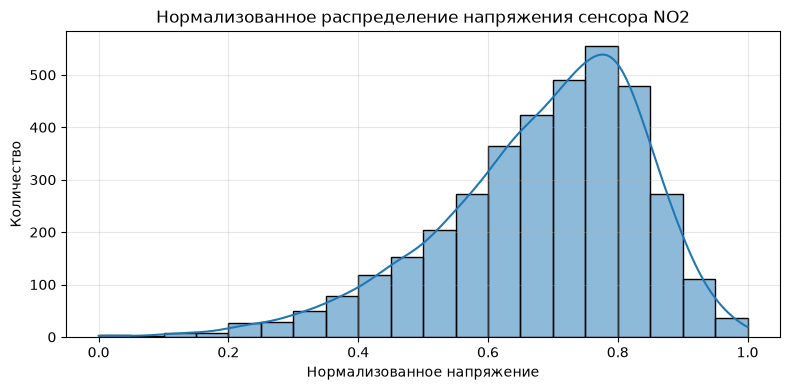

Новый минимум: 0.0
Новый максимум: 1.0
Новое среднее: 0.6838677930039768


In [9]:
min_no2 = no2.min()
max_no2 = no2.max()
no2_normalized = (no2 - min_no2) / (max_no2 - min_no2)

fig, axes = plt.subplots(figsize=(8, 4))
sns.histplot(
    data=no2_normalized,
    kde=True,
    ax=axes,
    bins=20,
)

axes.set_title("Нормализованное распределение напряжения сенсора NO2")
axes.set_xlabel("Нормализованное напряжение")
axes.set_ylabel("Количество")
axes.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Новый минимум:", no2_normalized.min())
print(f"Новый максимум:", no2_normalized.max())
print(f"Новое среднее:", no2_normalized.mean())

### Independence & Estimations
Для проверки состоятельности оценки проверим, как среднее значение ведет себя при увеличении количества случайных показаний сенсора.

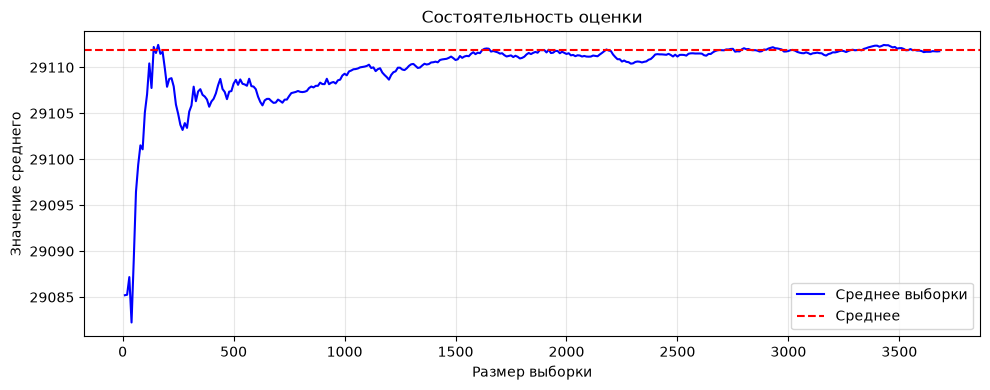

In [27]:
random_no2 = no2.sample(frac=1, random_state=40).values

sizes = np.arange(10, len(random_no2), 10)
means = [random_no2[:n].mean() for n in sizes]

plt.figure(figsize=(10, 4))
plt.plot(sizes, means, label='Среднее выборки', color='blue')
plt.axhline(no2.mean(), color='red', linestyle='--', label='Среднее')

plt.title('Состоятельность оценки')
plt.xlabel('Размер выборки')
plt.ylabel('Значение среднего')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Можно заметить, как значение среднего перестает колебаться и сводится к исходному при увеличении размера выборки.
После отметки в 600 показаний, среднее перестает сильно колебаться. Возьмем выборку размером в 600 значений и проверим ее статистику.

In [38]:
n_samples = 600

no_return = no2.sample(n=n_samples, replace=False, random_state=40)
with_return = no2.sample(n=n_samples, replace=True, random_state=40)

def get_stat(data, column_name):
    stats = {
        "Сумма": data.sum(),
        "Среднее": data.mean(),
        "Медиана": data.median(),
        "Минимум": data.min(),
        "Максимум": data.max(),
        "Стандартное отклонение": data.std(),
        "95-й перцентиль": data.quantile(0.95),
        "Дисперсия": data.var(),
        "Мода": data.mode().iloc[0],
    }
    return pd.DataFrame(stats.values(), index=stats.keys(), columns=[column_name])

df_gen = get_stat(no2, "Генеральная совокупность")
df_no_r = get_stat(no_return, "Без возвращения ")
df_with_r = get_stat(with_return, "С возвращением")

table = pd.concat([df_gen, df_no_r, df_with_r], axis=1)
display(table)

,Генеральная совокупность,Без возвращения,С возвращением
Сумма,1.073062e+08,1.746457e+07,1.746633e+07
Среднее,2.911184e+04,2.910761e+04,2.911055e+04
Медиана,2.912804e+04,2.912511e+04,2.912652e+04
Минимум,2.871500e+04,2.873198e+04,2.879690e+04
Максимум,2.929528e+04,2.929450e+04,2.927598e+04
Стандартное отклонение,9.041963e+01,9.166015e+01,8.787437e+01
95-й перцентиль,2.923317e+04,2.922880e+04,2.922898e+04
Дисперсия,8.175709e+03,8.401583e+03,7.721905e+03
Мода,2.912609e+04,2.906138e+04,2.921608e+04


Все данные, кроме суммы, очень близки к генеральной совокупности, что показывает выборку объемом 600 подходящей для суждения о ней.
Дисперсия выборки с возвращением заметно ниже, так как в нее могли попасть продублированные строки, в остальном данные не отличаются.
Выборка без возвращения в целом более похожа на оригинальную

## Random Variable 03: Сигнал сенсора температуры (ASE_T)

### Description
Случайная величина 3 — значение напряжения на сенсоре температуры, измеряемое на автомобильном перекрестке. Показание сенсора нельзя просто рассчитать по формуле, так как температура воздуха зависит от многих факторов: погоды, времени суток, количества машин и ветра. Также присутствует погрешность самого сенсора и броуновское движение молекул воздуха.

### EDA & Distribution


Размер данных до очистки: 3739 наблюдений.
Размер данных после очистки: 3736 наблюдений.



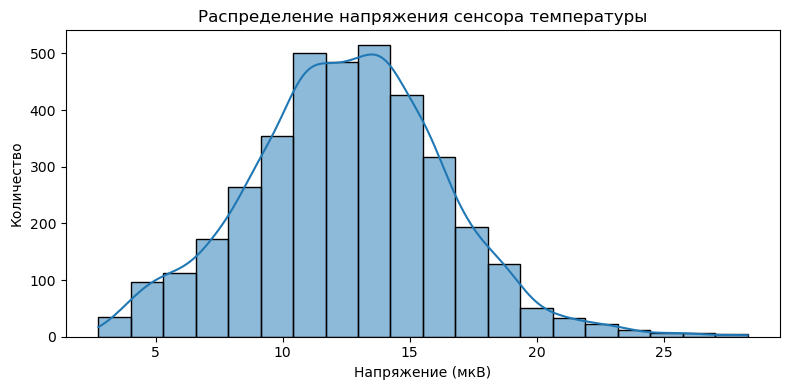

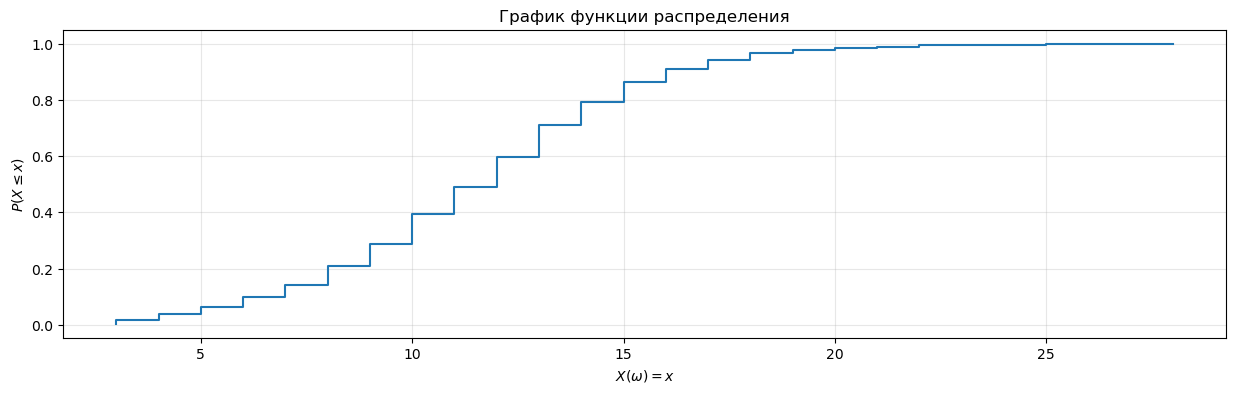


Сумма: 46886.3627801
Среднее: 12.549882971118842
Медиана: 12.594052795
Минимум: 2.752066326
Максимум: 28.28757534
Стандартное отклонение: 3.8424041112466325
95-й перцентиль: 18.747636445
Дисперсия: 14.764069354125024
Мода: 8.736985326


In [5]:
temp_all = sensors['ASE_T']
temp = sensors['ASE_T'].dropna()

print(f"\nРазмер данных до очистки: {temp_all.shape[0]} наблюдений.")
print(f"Размер данных после очистки: {temp.shape[0]} наблюдений.\n")

temp.head(5)

# распределения
fig, axes = plt.subplots(figsize=(8, 4))

sns.histplot(
    data=temp,
    kde=True,
    ax=axes,
    bins=20
)
axes.set_title("Распределение напряжения сенсора температуры")
axes.set_xlabel("Напряжение (мкВ)")
axes.set_ylabel("Количество")

plt.tight_layout()
plt.show()


# график ф-ции распределения
temp_round = temp.apply(lambda x: int(round(x)))
voltage = temp_round.value_counts().reset_index()
voltage['p_i'] = voltage['count'].apply(lambda x: x/temp.shape[0])

p_accum = 0

def P_func(x):
    global p_accum
    p_accum += x
    return p_accum

voltage = voltage.sort_values(by='ASE_T')
voltage['P'] = voltage['p_i'].apply(lambda x: P_func(x))

fig, ax = plt.subplots(figsize=(15, 4))
ax.step(voltage['ASE_T'], voltage['P'])
ax.set_title("График функции распределения")
ax.set_xlabel(r"$X(\omega) = x$")
ax.set_ylabel(r"$P(X \leq x)$")
ax.grid(True, alpha=0.3)

plt.show()

# остальные метрики
print(f"\nСумма:", temp.sum())
print("Среднее:", temp.mean())
print("Медиана:", temp.median())
print("Минимум:", temp.min())
print("Максимум:", temp.max())
print("Стандартное отклонение:", temp.std())
print("95-й перцентиль:", temp.quantile(0.95))
print("Дисперсия:", temp.var())
print("Мода:", temp.mode().iloc[0])

#### Математическая база распределения
Сенсор измеряет напряжение, на что влияет множество мелких случайных факторов (погода, ветер, машины, погрешность прибора). Если случайная величина формируется под воздействием множества независимых факторов, ее распределение стремится к нормальному.

Физически — температура воздуха на перекрестке меняется в течение дня, а также под влиянием автомобильных выбросов тепла. Эти колебания (например, из-за частых машин) приводят к асимметрии графика распределения и образованию вытянутого хвоста.

Математически плотность вероятности асимметричного нормального распределения задается:
$$f(x) = \frac{2}{\omega} \phi\left(\frac{x - \xi}{\omega}\right) \Phi\left(\alpha \left(\frac{x - \xi}{\omega}\right)\right)$$

Где:
* $\phi(t)$ — стандартная нормальная плотность распределения.
* $\Phi(t)$ — функция распределения стандартного нормального закона.
* $\xi$ — параметр сдвига.
* $\omega$ — параметр масштаба.
* $\alpha$ — параметр асимметрии.

Нулевая гипотеза: распределение напряжения сенсора температуры соответствует нормальному, альтернативная: распределение отличается от нормального, присутствует асимметрия

In [10]:
import scipy.stats as stats

stat, p_value = stats.normaltest(temp)

print(f"Статистика критерия: {stat}")
print(f"p-value: {p_value}")

if p_value < 0.05:
    print("Нулевая гипотеза не верна")
else:
    print("Нулевая гипотеза верна")

Статистика критерия: 33.48183282258036
p-value: 5.364291633817727e-08
Нулевая гипотеза не верна


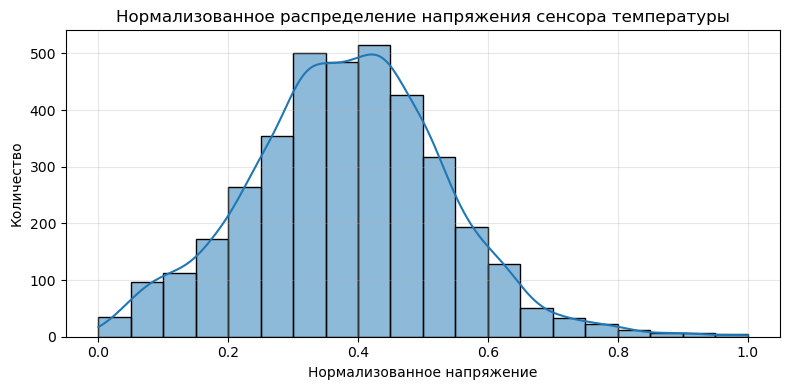

Новый минимум: 0.0
Новый максимум: 1.0
Новое среднее: 0.38369380613275145


In [11]:
min_temp = temp.min()
max_temp = temp.max()
temp_normalized = (temp - min_temp) / (max_temp - min_temp)

fig, axes = plt.subplots(figsize=(8, 4))
sns.histplot(
    data=temp_normalized,
    kde=True,
    ax=axes,
    bins=20,
)
axes.set_title("Нормализованное распределение напряжения сенсора температуры")
axes.set_xlabel("Нормализованное напряжение")
axes.set_ylabel("Количество")
axes.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Новый минимум:", temp_normalized.min())
print(f"Новый максимум:", temp_normalized.max())
print(f"Новое среднее:", temp_normalized.mean())

### Independence & Estimations
Для проверки состоятельности оценки проверим, как среднее значение ведет себя при увеличении количества случайных показаний сенсора.

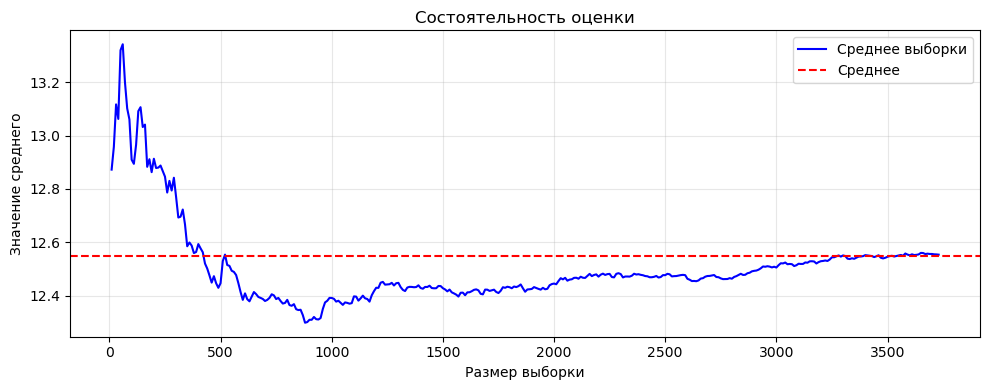

In [12]:
random_temp = temp.sample(frac=1, random_state=40).values

sizes = np.arange(10, len(random_temp), 10)
means = [random_temp[:n].mean() for n in sizes]

plt.figure(figsize=(10, 4))
plt.plot(sizes, means, label='Среднее выборки', color='blue')
plt.axhline(temp.mean(), color='red', linestyle='--', label='Среднее')

plt.title('Состоятельность оценки')
plt.xlabel('Размер выборки')
plt.ylabel('Значение среднего')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Можно заметить, как значение среднего перестает колебаться и сводится к исходному при увеличении размера выборки.
После отметки в 600 показаний, среднее перестает сильно колебаться. Возьмем выборку размером в 600 значений и проверим ее статистику.

In [13]:
n_samples = 600

no_return = temp.sample(n=n_samples, replace=False, random_state=40)
with_return = temp.sample(n=n_samples, replace=True, random_state=40)

def get_stat(data, column_name):
    stats = {
        "Сумма": data.sum(),
        "Среднее": data.mean(),
        "Медиана": data.median(),
        "Минимум": data.min(),
        "Максимум": data.max(),
        "Стандартное отклонение": data.std(),
        "95-й перцентиль": data.quantile(0.95),
        "Дисперсия": data.var(),
        "Мода": data.mode().iloc[0],
    }
    return pd.DataFrame(stats.values(), index=stats.keys(), columns=[column_name])

df_gen = get_stat(temp, "Генеральная совокупность")
df_no_r = get_stat(no_return, "Без возвращения ")
df_with_r = get_stat(with_return, "С возвращением")

table = pd.concat([df_gen, df_no_r, df_with_r], axis=1)
display(table)

,Генеральная совокупность,Без возвращения,С возвращением
Сумма,46886.362780,7430.257399,7604.712319
Среднее,12.549883,12.383762,12.674521
Медиана,12.594053,12.568173,12.834649
Минимум,2.752066,3.220754,2.752066
Максимум,28.287575,26.637090,25.848898
Стандартное отклонение,3.842404,3.698433,3.764880
95-й перцентиль,18.747636,18.123621,18.818729
Дисперсия,14.764069,13.678408,14.174325
Мода,8.736985,3.220754,13.043959


Все данные, кроме суммы, очень близки к генеральной совокупности, что показывает выборку объемом 600 подходящей для суждения о ней.
Дисперсия выборки с возвращением заметно ниже, так как в нее могли попасть продублированные строки, в остальном данные не отличаются.
Выборка без возвращения в целом более похожа на оригинальную. Также заметим что, в отличие от NO2, распределение температуры имеет несколько пиков, что физически объясняется изменением температуры в течение суток, а тест на нормальность подтверждает, что распределение не является нормальным